<a href="https://colab.research.google.com/github/arshiafreen090/Basic_DL/blob/main/mnist_num_dectection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder , StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import Perceptron    # Used for simple linear classification tasks.

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tensorflow.keras.models import Sequential     # Sequential lets you build a neural network layer-by-layer in Keras.

from tensorflow.keras.layers import Dense     #Dense makes the final predictions
from tensorflow.keras.layers import Conv2D     # Conv2D extracts features
from tensorflow.keras.layers import Flatten    # Flatten reshapes them

from tensorflow.keras.layers import MaxPooling2D     # MaxPooling2D reduces size
from tensorflow.keras.layers import Dropout          # Dropout prevents overfitting

from tensorflow.keras.utils import to_categorical     # converts numeric class labels into one-hot encoded format for training classification models


In [4]:
df = pd.read_csv("/content/train.csv")
df_test = pd.read_csv("/content/test.csv")

In [7]:
df.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,4,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [8]:
df_test.head()

,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,0,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [9]:
df.shape

(8026, 785)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8026 entries, 0 to 8025
Columns: 785 entries, label to pixel783
dtypes: float64(392), int64(393)
memory usage: 48.1 MB


In [12]:
#preprocess
X_train = df.drop("label", axis=1).values
y_train = df["label"].values
X_test = df_test.values

In [13]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

In [14]:
X_train_img = X_train.reshape(-1, 28, 28)
X_test_img = X_test.reshape(-1, 28, 28)

In [16]:
y_train_cat = to_categorical(y_train, 10)

# Perceptrons

In [17]:
perceptron = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(10, activation="softmax")])

In [18]:
perceptron.compile(optimizer="sgd", loss="categorical_crossentropy", metrics=["accuracy"])


In [20]:
# Fit the perceptrons using a 10% validation split from training data
history_percp = perceptron.fit(X_train_img, y_train_cat, epochs=5, batch_size=32, validation_split=0.1, verbose=1)

Epoch 1/5
226/226 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6186 - loss: 1.5442 - val_accuracy: 0.7584 - val_loss: nan
Epoch 2/5
226/226 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8071 - loss: 0.9447 - val_accuracy: 0.8157 - val_loss: nan
Epoch 3/5
226/226 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8375 - loss: 0.7502 - val_accuracy: 0.8394 - val_loss: nan
Epoch 4/5
226/226 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8524 - loss: 0.6534 - val_accuracy: 0.8468 - val_loss: nan
Epoch 5/5
226/226 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8575 - loss: 0.5938 - val_accuracy: 0.8593 - val_loss: nan


In [24]:
predictions = perceptron.predict(X_test_img)
predicted_classes = np.argmax(predictions, axis=1)

270/270 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [27]:
# Retrieve and print the final validation accuracy
train_acc = history_percp.history['accuracy'][-1]
val_acc = history_percp.history['val_accuracy'][-1]

print(f"Final Training Accuracy: {train_acc * 100:.2f}%")
print(f"Final Validation Accuracy: {val_acc * 100:.2f}%")

Final Training Accuracy: 85.75%
Final Validation Accuracy: 85.93%


# ANN

In [28]:
# Build the ANN architecture
ann = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
    ])

In [51]:
#compling the ANN
ann.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

In [31]:
# Fit the ANN using a 10% validation split from training data
history_ann = ann.fit(X_train_img, y_train_cat, epochs=5, batch_size=32, validation_split=0.1, verbose=1)

Epoch 1/5
226/226 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8249 - loss: 0.6069 - val_accuracy: 0.8842 - val_loss: nan
Epoch 2/5
226/226 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9234 - loss: 0.2572 - val_accuracy: 0.9091 - val_loss: nan
Epoch 3/5
226/226 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9500 - loss: 0.1758 - val_accuracy: 0.9240 - val_loss: nan
Epoch 4/5
226/226 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9655 - loss: 0.1271 - val_accuracy: 0.9166 - val_loss: nan
Epoch 5/5
226/226 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9733 - loss: 0.0946 - val_accuracy: 0.9315 - val_loss: nan


In [32]:
# Retrieve and print the final validation accuracy for the ANN
acc_ann = history_ann.history['val_accuracy'][-1]
print(f"ANN Validation Accuracy: {acc_ann * 100:.2f}%")

ANN Validation Accuracy: 93.15%


# CNN

In [33]:
# Reshape the data for CNN (adding a single channel dimension)
X_train_cnn = X_train_img.reshape(-1, 28, 28, 1)
X_test_cnn = X_test_img.reshape(-1, 28, 28, 1)

In [34]:
# Build the CNN architecture
cnn = Sequential([
    Conv2D(32, kernel_size=(3,3), activation="relu", input_shape=(28,28,1)),
    MaxPooling2D(pool_size=(2,2)),
    Conv2D(64, kernel_size=(3,3), activation="relu"),
    MaxPooling2D(pool_size=(2,2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(10, activation="softmax")
])

In [35]:
# Compile the CNN
cnn.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

In [36]:
# Fit the CNN using a 10% validation split from training data
history_cnn = cnn.fit(X_train_cnn, y_train_cat, epochs=5, batch_size=32, validation_split=0.1, verbose=1)

Epoch 1/5
226/226 ━━━━━━━━━━━━━━━━━━━━ 9s 31ms/step - accuracy: 0.7747 - loss: 0.7026 - val_accuracy: 0.9352 - val_loss: nan
Epoch 2/5
226/226 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.9337 - loss: 0.2256 - val_accuracy: 0.9440 - val_loss: nan
Epoch 3/5
226/226 ━━━━━━━━━━━━━━━━━━━━ 7s 31ms/step - accuracy: 0.9553 - loss: 0.1485 - val_accuracy: 0.9539 - val_loss: nan
Epoch 4/5
226/226 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.9633 - loss: 0.1210 - val_accuracy: 0.9614 - val_loss: nan
Epoch 5/5
226/226 ━━━━━━━━━━━━━━━━━━━━ 7s 31ms/step - accuracy: 0.9690 - loss: 0.1031 - val_accuracy: 0.9651 - val_loss: nan


In [37]:
# Retrieve and print the final validation accuracy for the CNN
acc_cnn = history_cnn.history['val_accuracy'][-1]
print(f"CNN Validation Accuracy: {acc_cnn * 100:.2f}%")

CNN Validation Accuracy: 96.51%


# Comparision

In [38]:
def plot_training(history, title):
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label="Train")
    plt.plot(history.history['val_accuracy'], label="Val")
    plt.title(f"{title} Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label="Train")
    plt.plot(history.history['val_loss'], label="Val")
    plt.title(f"{title} Loss")
    plt.legend()
    plt.show()

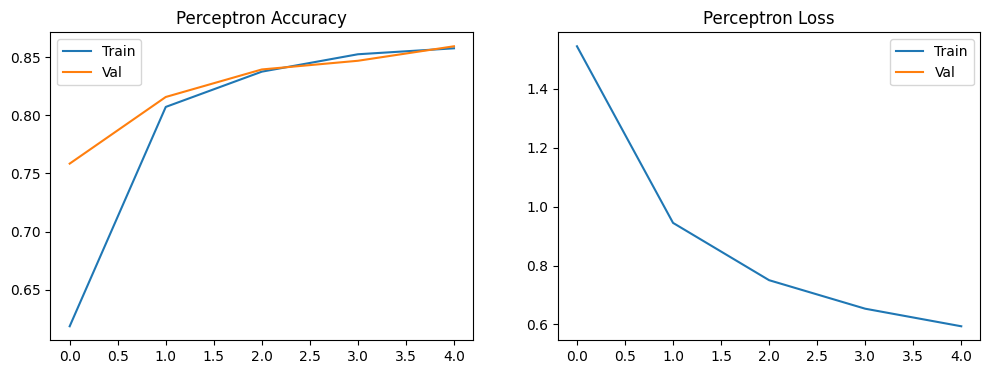

In [39]:
# Plot learning curves for the Perceptron
plot_training(history_percp, "Perceptron")

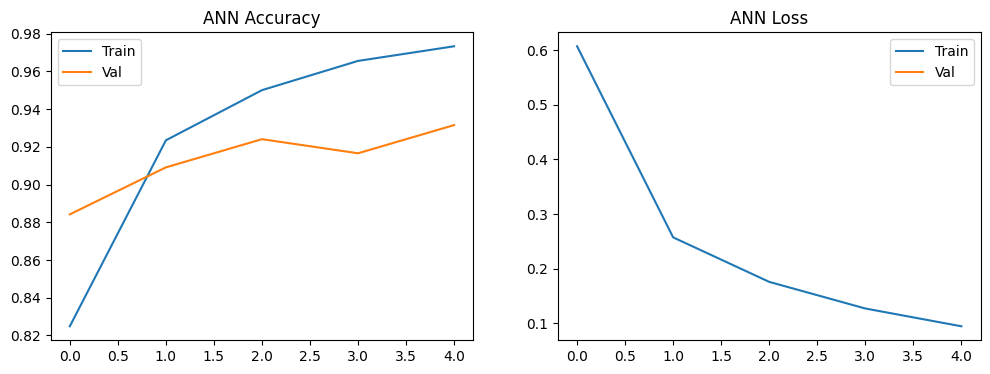

In [40]:
# Plot learning curves for the ANN
plot_training(history_ann, "ANN")

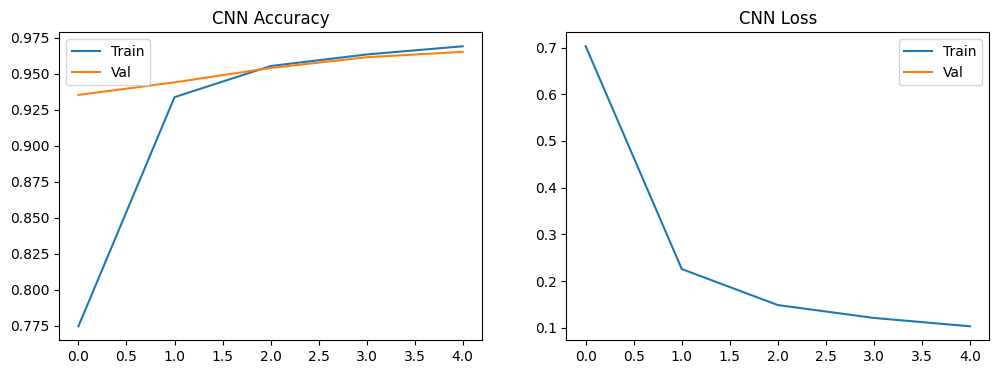

In [41]:
# Plot learning curves for the CNN
plot_training(history_cnn, "CNN")

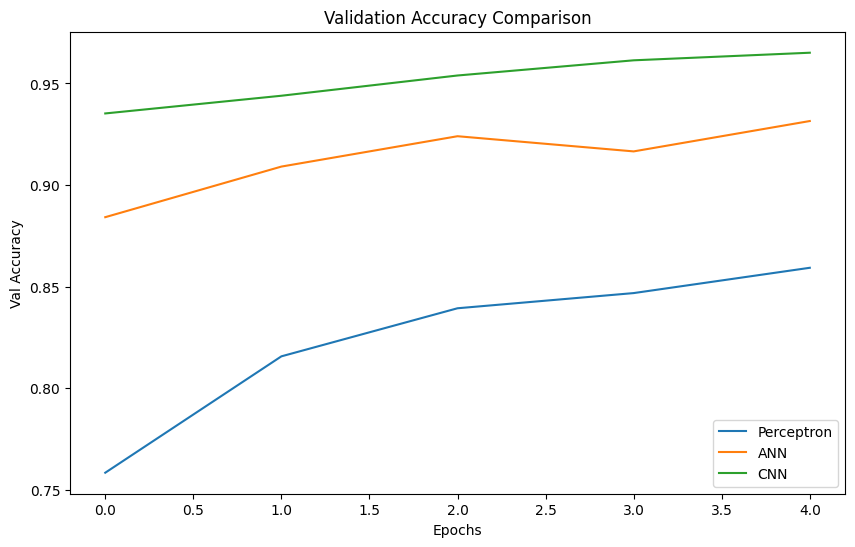

In [43]:
plt.figure(figsize=(10,6))
plt.plot(history_percp.history['val_accuracy'], label="Perceptron")
plt.plot(history_ann.history['val_accuracy'], label="ANN")
plt.plot(history_cnn.history['val_accuracy'], label="CNN")
plt.title("Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Val Accuracy")
plt.legend()
plt.show()

In [46]:
def show_side_by_side(models, model_names, X, X_cnn, y_true, n=5):
    idxs = np.random.choice(len(X), n, replace=False)
    plt.figure(figsize=(15, 6))
    for i, idx in enumerate(idxs):
        plt.subplot(2, n, i+1)
        plt.imshow(X[idx].reshape(28, 28), cmap="gray")
        plt.axis("off")
        plt.title(f"True: {y_true[idx]}")
        preds = [np.argmax(model.predict(X_cnn[idx].reshape(1, 28, 28, 1) if name == "CNN" else X[idx].reshape(1, 28, 28)))
                 for model, name in zip(models, model_names)]
        plt.subplot(2, n, n+i+1)
        plt.axis("off")
        plt.title("\n".join(f"{n}: {p}" for n, p in zip(model_names, preds)))
    plt.tight_layout()
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


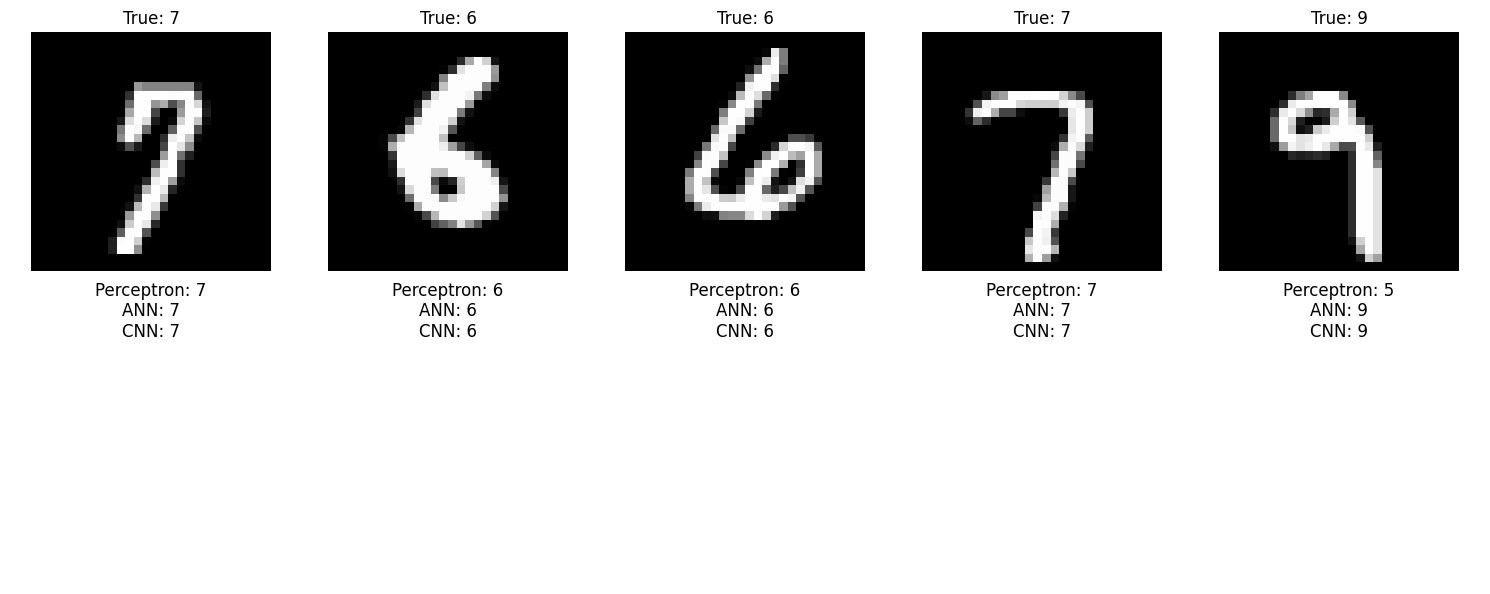

In [48]:
show_side_by_side([perceptron, ann, cnn], ["Perceptron", "ANN", "CNN"], X_train_img, X_train_cnn, y_train, 5)

251/251 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step


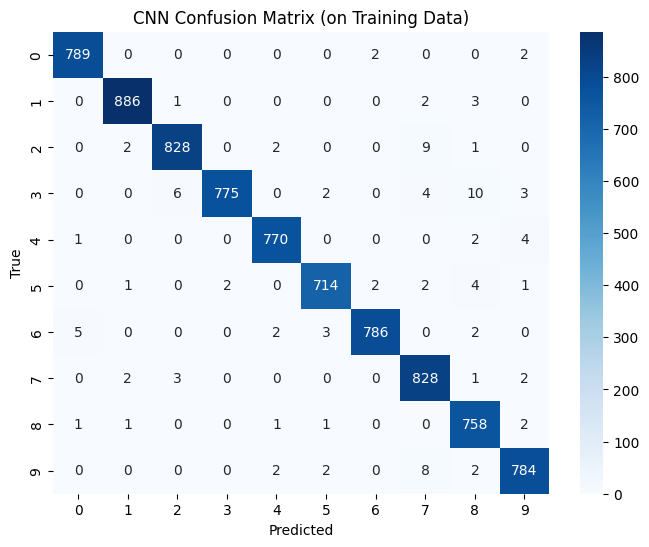

In [49]:
# Generate predictions on the labeled training dataset
y_pred_cnn = np.argmax(cnn.predict(X_train_cnn), axis=1)

# Compute and plot confusion matrix for the CNN model
cm = confusion_matrix(y_train, y_pred_cnn)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("CNN Confusion Matrix (on Training Data)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

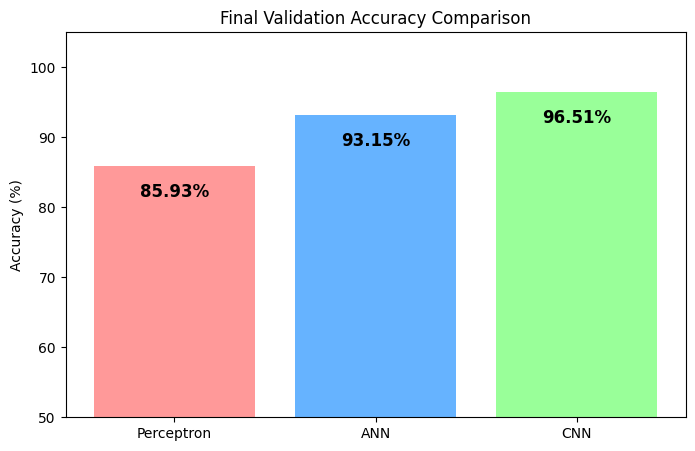

In [50]:
# Map accuracy values to the correct defined variables
final_accs = [val_acc * 100, acc_ann * 100, acc_cnn * 100]
models = ["Perceptron", "ANN", "CNN"]

# Plot final validation accuracy comparison
plt.figure(figsize=(8,5))
bars = plt.bar(models, final_accs, color=['#ff9999','#66b3ff','#99ff99'])
plt.title("Final Validation Accuracy Comparison")
plt.ylabel("Accuracy (%)")
for bar, acc in zip(bars, final_accs):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() - 5, f"{acc:.2f}%",
             ha='center', va='bottom', fontsize=12, fontweight='bold')
plt.ylim(50, 105)
plt.show()